In [1]:
import os
print(os.getcwd())

C:\Users\LENOVO\OneDrive\Documents\Project\notebooks


In [2]:
import os
print(os.listdir("../data"))

['BlackFriday.csv']


In [3]:
import pandas as pd

In [4]:
df = pd.read_csv("../data/BlackFriday.csv")
df.head()

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,1000001,P00069042,F,0-17,10,A,2,0,3,NaN,NaN,8370
1,1000001,P00248942,F,0-17,10,A,2,0,1,6.0,14.0,15200
2,1000001,P00087842,F,0-17,10,A,2,0,12,NaN,NaN,1422
3,1000001,P00085442,F,0-17,10,A,2,0,12,14.0,NaN,1057
4,1000002,P00285442,M,55+,16,C,4+,0,8,NaN,NaN,7969


## Store the data in a DATABASE

In [5]:
#Store the data in the dataset of sqlite3

import sqlite3

In [6]:
conn = sqlite3.connect("../blackfriday.db")
df.to_sql("sales", conn, if_exists="replace", index=False)
print("Database created successfully")

Database created successfully


In [7]:
query = "SELECT * FROM sales LIMIT 5"
check_df = pd.read_sql(query, conn)
check_df

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,1000001,P00069042,F,0-17,10,A,2,0,3,NaN,NaN,8370
1,1000001,P00248942,F,0-17,10,A,2,0,1,6.0,14.0,15200
2,1000001,P00087842,F,0-17,10,A,2,0,12,NaN,NaN,1422
3,1000001,P00085442,F,0-17,10,A,2,0,12,14.0,NaN,1057
4,1000002,P00285442,M,55+,16,C,4+,0,8,NaN,NaN,7969


In [8]:
query = "SELECT name FROM sqlite_master WHERE type='table';"
tables = pd.read_sql(query, conn)
tables

,name
0,sales


## Structual information of Dataset

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 550068 entries, 0 to 550067
Data columns (total 12 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   User_ID                     550068 non-null  int64  
 1   Product_ID                  550068 non-null  object 
 2   Gender                      550068 non-null  object 
 3   Age                         550068 non-null  object 
 4   Occupation                  550068 non-null  int64  
 5   City_Category               550068 non-null  object 
 6   Stay_In_Current_City_Years  550068 non-null  object 
 7   Marital_Status              550068 non-null  int64  
 8   Product_Category_1          550068 non-null  int64  
 9   Product_Category_2          376430 non-null  float64
 10  Product_Category_3          166821 non-null  float64
 11  Purchase                    550068 non-null  int64  
dtypes: float64(2), int64(5), object(5)
memory usage: 50.4+ MB


In [10]:
print("Missing Values:")
print(df.isnull().sum())
print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values:
User_ID                            0
Product_ID                         0
Gender                             0
Age                                0
Occupation                         0
City_Category                      0
Stay_In_Current_City_Years         0
Marital_Status                     0
Product_Category_1                 0
Product_Category_2            173638
Product_Category_3            383247
Purchase                           0
dtype: int64

Duplicate Rows:
0


In [11]:
df[['Product_Category_2', 'Product_Category_3']]

,Product_Category_2,Product_Category_3
0,NaN,NaN
1,6.0,14.0
2,NaN,NaN
3,14.0,NaN
4,NaN,NaN
...,...,...
550063,NaN,NaN
550064,NaN,NaN
550065,NaN,NaN
550066,NaN,NaN


In [12]:
df['Product_Category_2'] = df['Product_Category_2'].fillna(0)
df['Product_Category_3'] = df['Product_Category_3'].fillna(0)

In [13]:
df['Product_Category_2'] = df['Product_Category_2'].astype(int)
df['Product_Category_3'] = df['Product_Category_3'].astype(int)

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 550068 entries, 0 to 550067
Data columns (total 12 columns):
 #   Column                      Non-Null Count   Dtype 
---  ------                      --------------   ----- 
 0   User_ID                     550068 non-null  int64 
 1   Product_ID                  550068 non-null  object
 2   Gender                      550068 non-null  object
 3   Age                         550068 non-null  object
 4   Occupation                  550068 non-null  int64 
 5   City_Category               550068 non-null  object
 6   Stay_In_Current_City_Years  550068 non-null  object
 7   Marital_Status              550068 non-null  int64 
 8   Product_Category_1          550068 non-null  int64 
 9   Product_Category_2          550068 non-null  int64 
 10  Product_Category_3          550068 non-null  int64 
 11  Purchase                    550068 non-null  int64 
dtypes: int64(7), object(5)
memory usage: 50.4+ MB


In [15]:
print(df[['Product_Category_2','Product_Category_3']].isnull().sum())

Product_Category_2    0
Product_Category_3    0
dtype: int64


In [16]:
df.shape

(550068, 12)

In [17]:
df.apply(lambda x:len(x.unique()))

User_ID                        5891
Product_ID                     3631
Gender                            2
Age                               7
Occupation                       21
City_Category                     3
Stay_In_Current_City_Years        5
Marital_Status                    2
Product_Category_1               20
Product_Category_2               18
Product_Category_3               16
Purchase                      18105
dtype: int64

In [18]:
df.describe()

,User_ID,Occupation,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
count,5.500680e+05,550068.000000,550068.000000,550068.000000,550068.000000,550068.000000,550068.000000
mean,1.003029e+06,8.076707,0.409653,5.404270,6.735436,3.841941,9263.968713
std,1.727592e+03,6.522660,0.491770,3.936211,6.215492,6.250712,5023.065394
min,1.000001e+06,0.000000,0.000000,1.000000,0.000000,0.000000,12.000000
25%,1.001516e+06,2.000000,0.000000,1.000000,0.000000,0.000000,5823.000000
50%,1.003077e+06,7.000000,0.000000,5.000000,5.000000,0.000000,8047.000000
75%,1.004478e+06,14.000000,1.000000,8.000000,14.000000,8.000000,12054.000000
max,1.006040e+06,20.000000,1.000000,20.000000,18.000000,18.000000,23961.000000


In [19]:
df.isnull().sum()

User_ID                       0
Product_ID                    0
Gender                        0
Age                           0
Occupation                    0
City_Category                 0
Stay_In_Current_City_Years    0
Marital_Status                0
Product_Category_1            0
Product_Category_2            0
Product_Category_3            0
Purchase                      0
dtype: int64

##### NOTE: Updated the dataset by removing the missing values and converting all the Product_Category into int values.  

## Store cleaned data in DATASET

In [20]:
df.to_sql("sales", conn, if_exists="replace", index=False)

550068

## Exploratory Data Analysis (EDA)

In [21]:
import seaborn as sns

In [22]:
import matplotlib.pyplot as plt

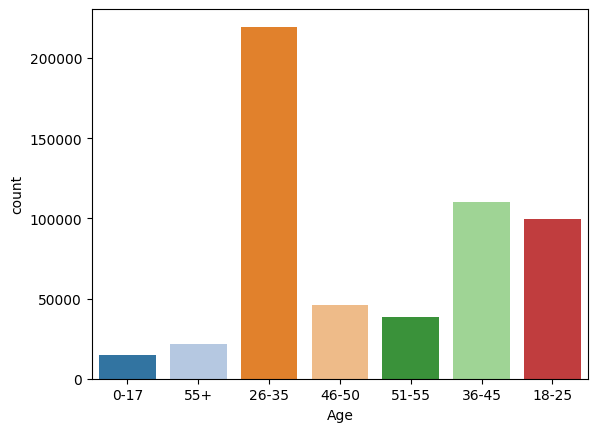

In [23]:
sns.countplot(data=df, x='Age', hue='Age', palette='tab20', legend=False)
plt.show()

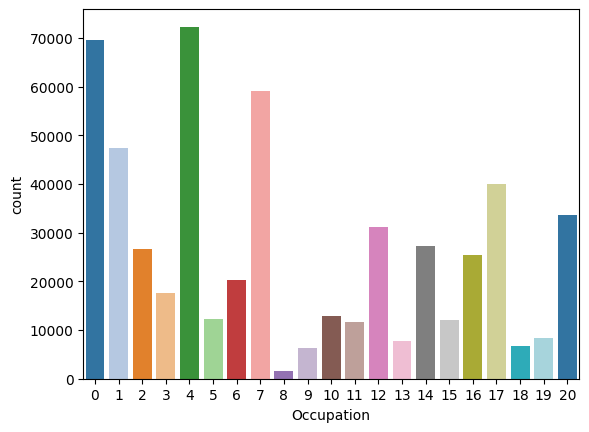

In [24]:
sns.countplot(data=df, x='Occupation', hue='Occupation', palette='tab20', legend=False)
plt.show()

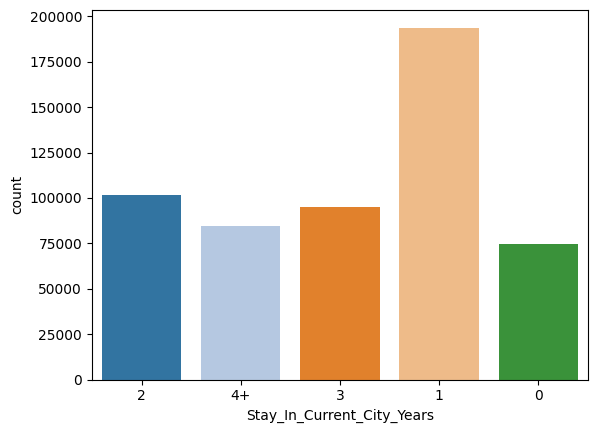

In [25]:
sns.countplot(data=df, x='Stay_In_Current_City_Years', hue='Stay_In_Current_City_Years', palette='tab20', legend=False)
plt.show()

Get the count of each metrics to predict properly. Then we wil also know how much skewed our dataset is.


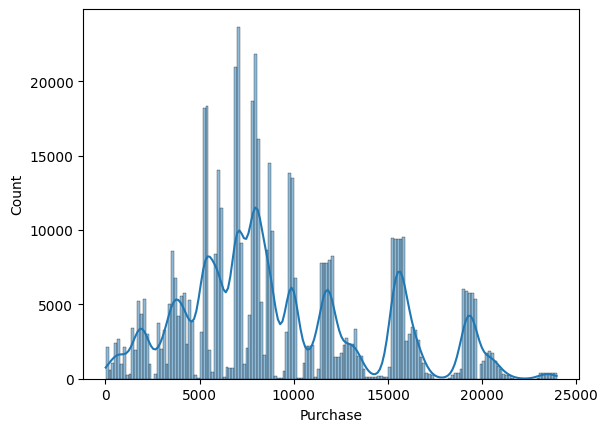

In [26]:
sns.histplot(df['Purchase'], kde=True)
plt.show()

##### NOTE: The Purchase distribution shows that mostly customers buy between the range of 5000 to 10000. Though the distribution is multimodel, indicating multiple highs and lows.

C:\Users\LENOVO\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


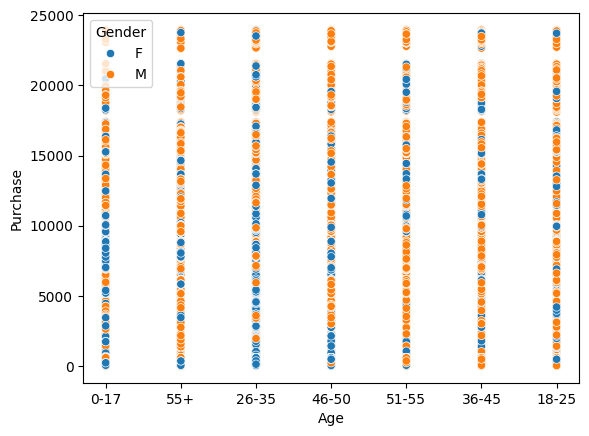

In [27]:
sns.scatterplot(
    x='Age',
    y='Purchase',
    hue='Gender',
    data=df
)
plt.show()

<Axes: xlabel='Age', ylabel='Purchase'>

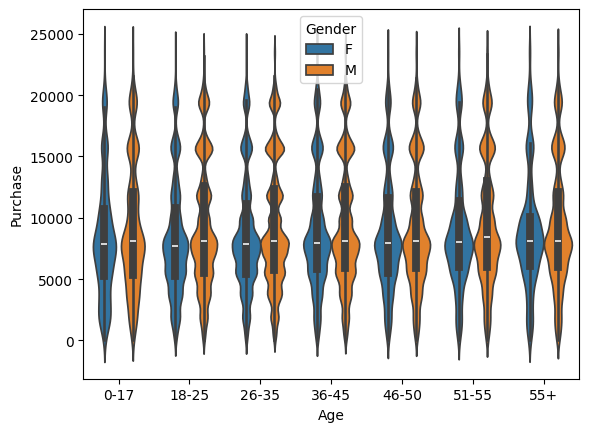

In [28]:
age_order = ['0-17','18-25','26-35','36-45','46-50','51-55','55+']

sns.violinplot(
    x='Age',
    y='Purchase',
    hue='Gender',
    data=df,
    order=age_order
)

##### NOTE: Age does not strongly affect purchase amount. Male and female purchase behavior looks similar even thogh there are more males than females.

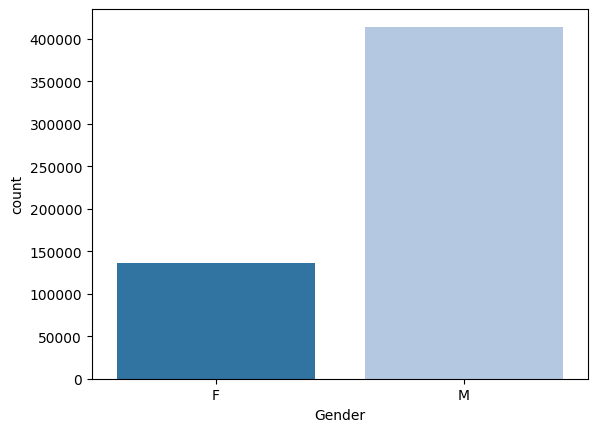

In [29]:
sns.countplot(data=df, x='Gender', hue='Gender', palette='tab20', legend=False)
plt.show()

<Axes: xlabel='Age', ylabel='Purchase'>

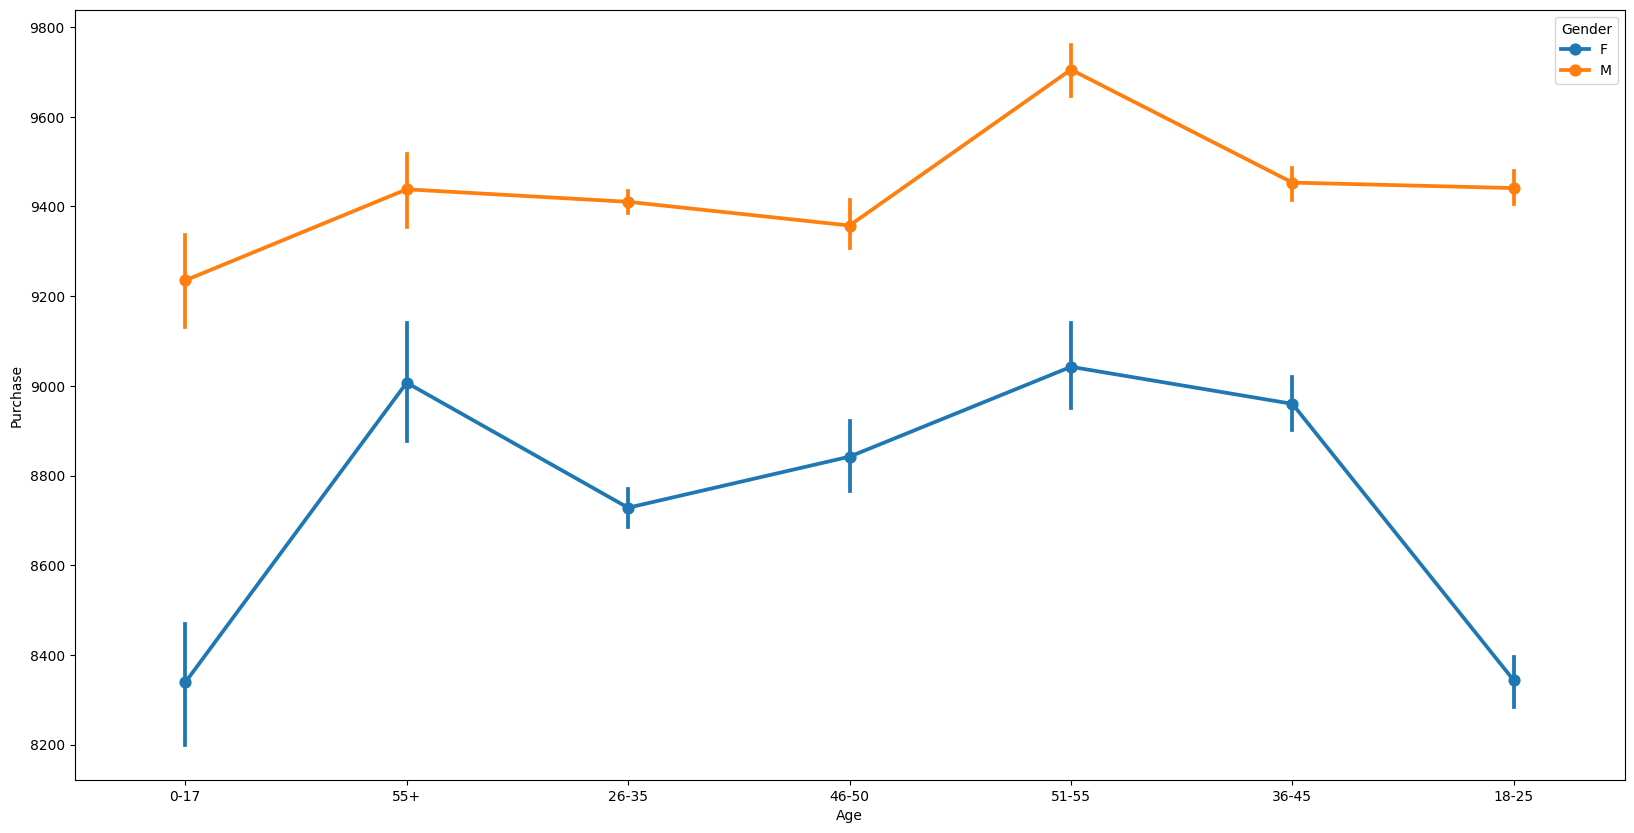

In [30]:
fig, ax=plt.subplots(figsize=(20,10))
sns.pointplot(data=df,x='Age',y='Purchase',hue='Gender',ax=ax)

##### NOTE: Males are spending more than the females and specially the males between the age group of 51- 55.

#### From the dataset we can say that 
#### Target Audience: Males with age limit 26- 55

<Axes: xlabel='Occupation', ylabel='Purchase'>

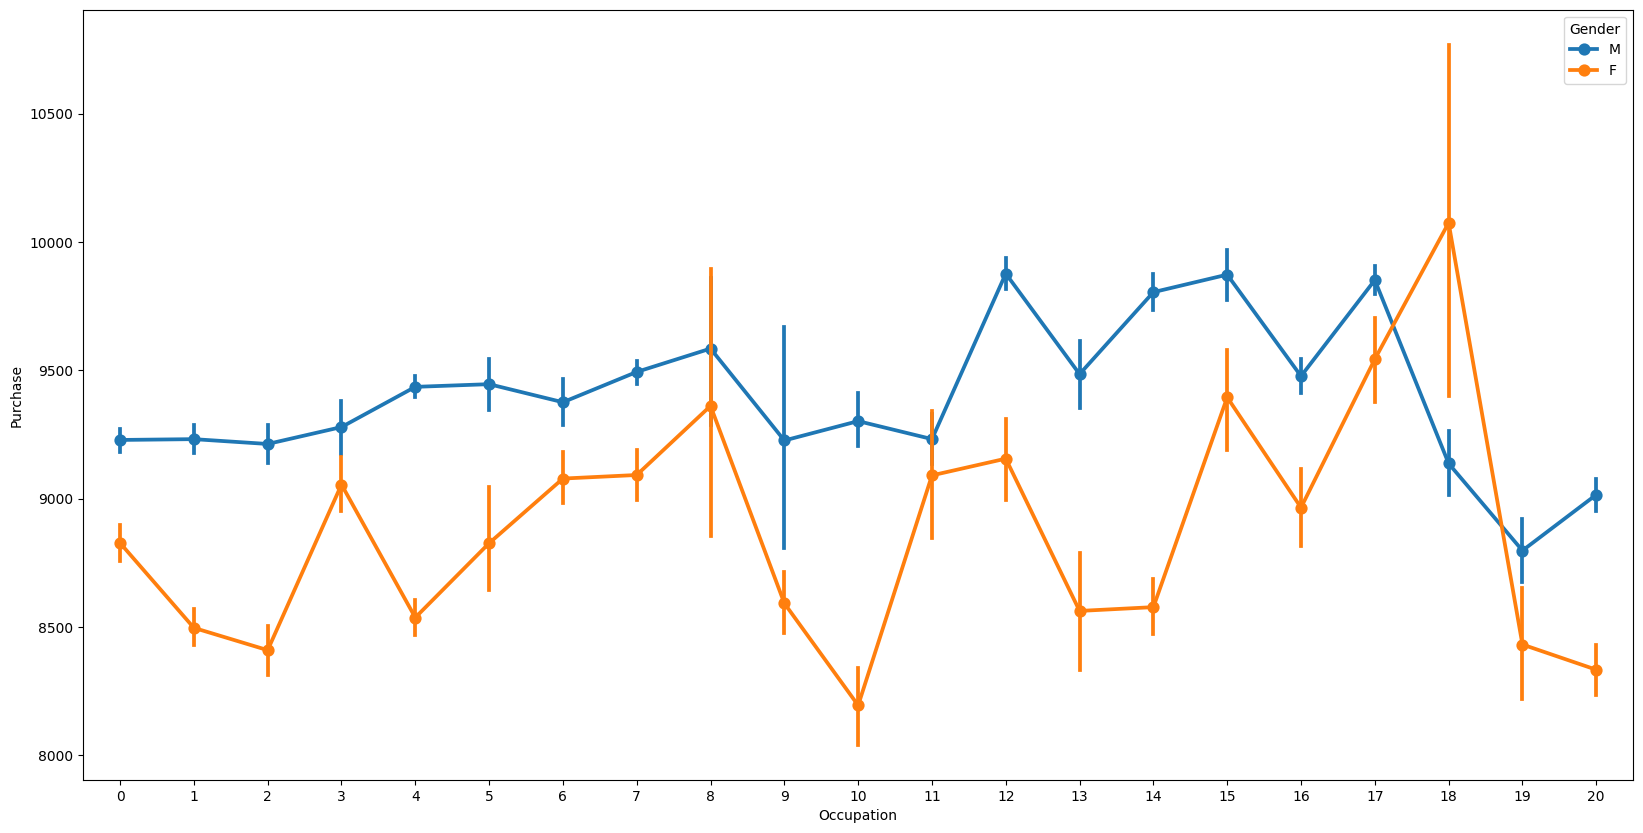

In [31]:
fig, ax=plt.subplots(figsize=(20,10))
sns.pointplot(data=df,x='Occupation',y='Purchase', hue='Gender',ax=ax)

##### NOTE: Occupation has some effect on spending; males with occupations 12, 14, 15 and 17 have higher chances of purchase than the rest. Females in occupation 18 have a higher likelihood of purchasing than the rest of the females.

<Axes: xlabel='Marital_Status', ylabel='Purchase'>

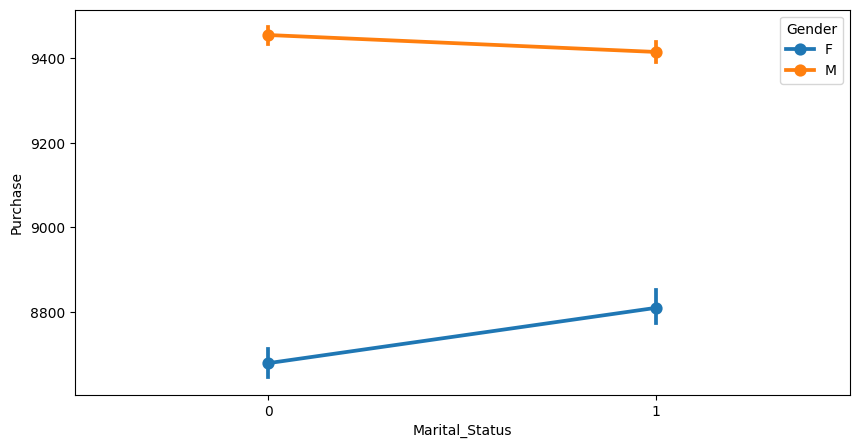

In [32]:
fig, ax=plt.subplots(figsize=(10,5))
sns.pointplot(data=df,x='Marital_Status',y='Purchase', hue='Gender',ax=ax)

Occupation 18 has both type of feamales the ones who spend a lot and also the ones who spend little considering the min and max values. Mean > Median so possibility of right skew.

<Axes: xlabel='Stay_In_Current_City_Years', ylabel='Purchase'>

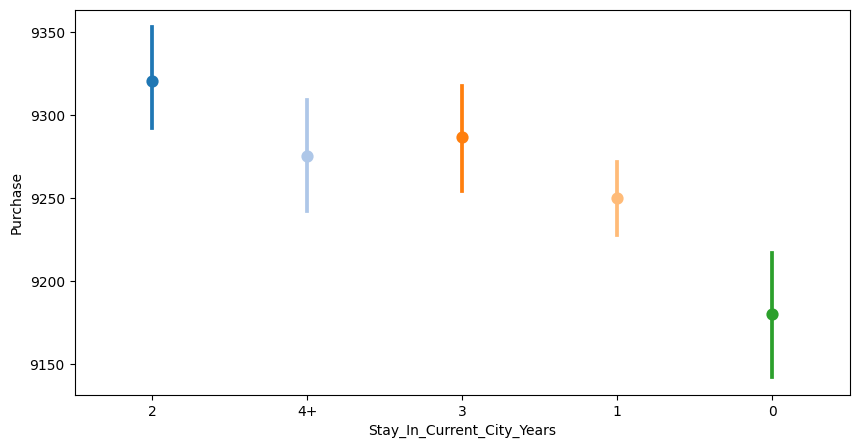

In [33]:
fig, ax=plt.subplots(figsize=(10,5))
sns.pointplot(data=df, x='Stay_In_Current_City_Years',y='Purchase', hue='Stay_In_Current_City_Years', palette='tab20',ax=ax)

In [34]:
female_occ18 = df[(df['Gender']=='F') & (df['Occupation']==18)]
female_occ18

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
16143,1002475,P00354342,F,26-35,18,A,2,0,5,11,0,5437
20144,1003184,P00122442,F,26-35,18,C,2,1,1,11,15,11597
20145,1003184,P00313542,F,26-35,18,C,2,1,5,8,0,8589
20146,1003184,P00258442,F,26-35,18,C,2,1,5,0,0,8789
20147,1003184,P00114042,F,26-35,18,C,2,1,5,14,0,7025
...,...,...,...,...,...,...,...,...,...,...,...,...
538050,1004815,P00193742,F,51-55,18,C,0,1,8,15,0,7955
538051,1004815,P00288342,F,51-55,18,C,0,1,8,0,0,3951
547589,1002475,P00370853,F,26-35,18,A,2,0,19,0,0,61
548799,1004231,P00372445,F,51-55,18,C,4+,0,20,0,0,238


In [35]:
female_occ18['Purchase'].describe()

count      230.000000
mean     10074.608696
std       5263.387084
min         61.000000
25%       7043.250000
50%       8745.000000
75%      12577.750000
max      23398.000000
Name: Purchase, dtype: float64

#### The analysis shows that Product_Category_1 and Product_Category_3 have moderate relationships with Purchase, indicating that purchase behavior varies across product categories. However, variables like User_ID, Occupation, and Marital_Status show negligible correlation

In [36]:
df.corr(numeric_only=True)['Purchase'].sort_values(ascending=False)

Purchase              1.000000
Product_Category_3    0.288501
Product_Category_2    0.052288
Occupation            0.020833
User_ID               0.004716
Marital_Status       -0.000463
Product_Category_1   -0.343703
Name: Purchase, dtype: float64

Unmarried females (0) ka average purchase ≈ 8680
Married females (1) ka average purchase ≈ 8810
Unmarried males (0) ka average purchase ≈ 9450
Married males (1) ka average purchase ≈ 9410

##### Overall observation
Male customers ka average purchase females se higher hai.
Female spending marriage ke baad slightly increase hui.
Male spending marriage ke baad slightly decrease hui.
Marital status ka effect hai, but gender ka effect stronger lag raha hai.

Lowest spending are the people who are living in the city for 0 years whereas the people staying in the city for 2 or more years are purchasing more.

<Axes: xlabel='City_Category', ylabel='Purchase'>

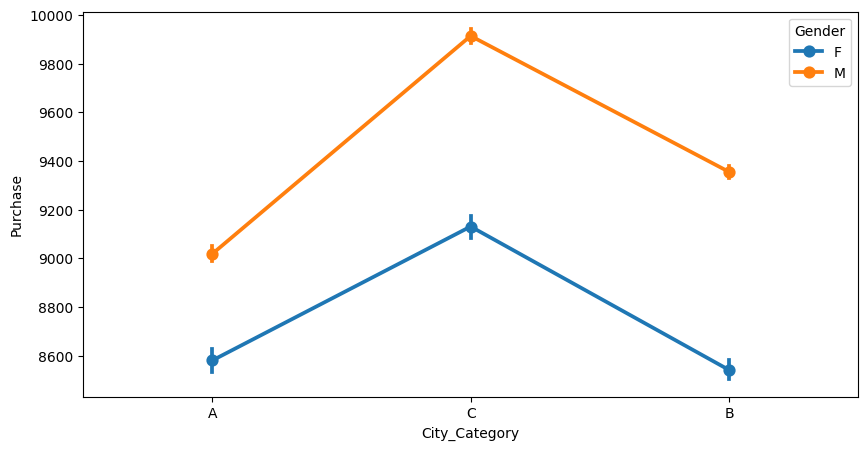

In [37]:
fig, ax=plt.subplots(figsize=(10,5))
sns.pointplot(data=df, x='City_Category',y='Purchase', hue='Gender',ax=ax)

<Axes: xlabel='City_Category', ylabel='Purchase'>

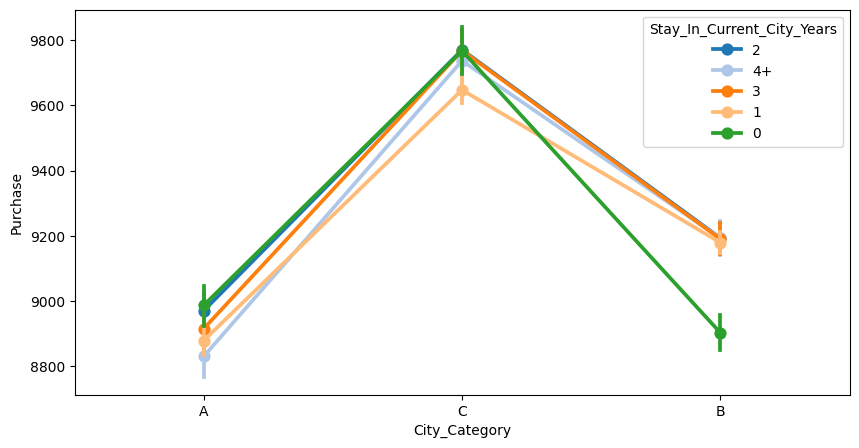

In [38]:
fig, ax=plt.subplots(figsize=(10,5))
sns.pointplot(data=df, x='City_Category',y='Purchase', hue='Stay_In_Current_City_Years', palette='tab20',ax=ax)

City Category matters more than Stay Duration:
Purchases vary significantly between cities (C > A > B).
Stay duration has only a minor effect, with purchase averages staying fairly stable. Purchases are relatively close across all groups (around 9150–9350).

<Axes: xlabel='City_Category', ylabel='Purchase'>

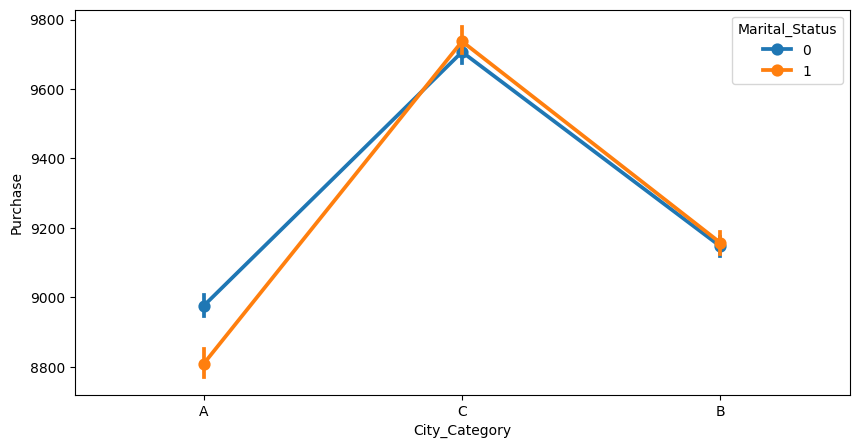

In [39]:
fig, ax=plt.subplots(figsize=(10,5))
sns.pointplot(data=df, x='City_Category',y='Purchase', hue='Marital_Status',ax=ax)

City Category dominates: Across gender, marital status, and stay duration, City C consistently shows the highest purchases, City B the lowest.

Demographics (gender, marital status):
Males spend more than females across all cities.

Marital status doesn’t create a big gap—both groups behave similarly.
Stay Duration: Length of stay in a city has only a minor effect compared to city type.

Most sold product: Product_Category_2
Total sold: 3704948


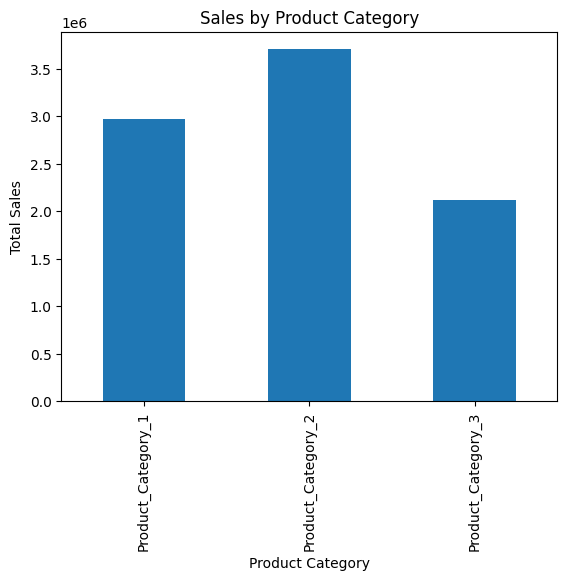

In [40]:
totals = df[['Product_Category_1', 'Product_Category_2', 'Product_Category_3']].sum()

# print most sold product
print("Most sold product:", totals.idxmax())
print("Total sold:", totals.max())

# plot
totals.plot(kind='bar')
plt.title("Sales by Product Category")
plt.ylabel("Total Sales")
plt.xlabel("Product Category")
plt.show()


               Product_Category_1  Product_Category_2  Product_Category_3
City_Category                                                            
A                          813387              977988              526424
B                         1242828             1549399              877512
C                          916501             1177561              709393


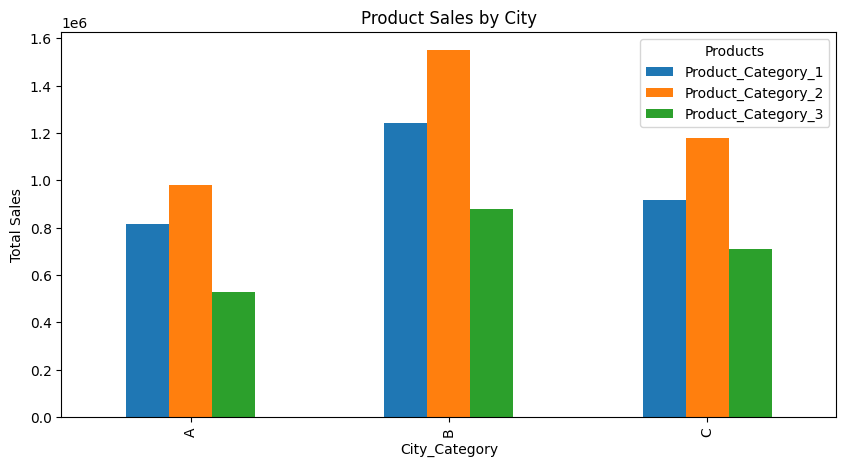

In [41]:
# group by city and sum products
city_product = df.groupby('City_Category')[['Product_Category_1', 'Product_Category_2', 'Product_Category_3']].sum()

# print result
print(city_product)

# plot
city_product.plot(kind='bar', figsize=(10,5))
plt.title("Product Sales by City")
plt.ylabel("Total Sales")
plt.xlabel("City_Category")
plt.legend(title="Products")
plt.show()

                Product_Category_1  Product_Category_2  Product_Category_3
Marital_Status                                                            
0                          1733758             2185357             1255425
1                          1238958             1519591              857904


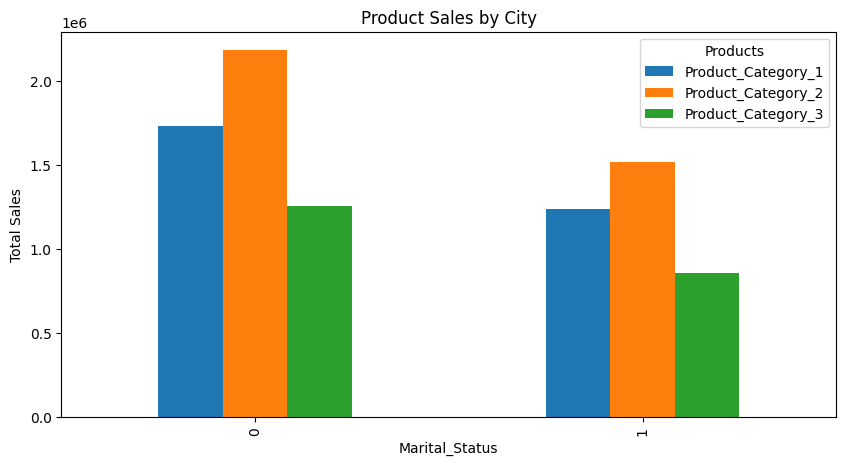

In [42]:
# group by city and sum products
city_product = df.groupby('Marital_Status')[['Product_Category_1', 'Product_Category_2', 'Product_Category_3']].sum()

# print result
print(city_product)

# plot
city_product.plot(kind='bar', figsize=(10,5))
plt.title("Product Sales by City")
plt.ylabel("Total Sales")
plt.xlabel("Marital_Status")
plt.legend(title="Products")
plt.show()

#### The Product Category 2 has the maximum number of sales. Product category 1 comes next and then Product Category 3. City C has the higest avarage purchase amount (people spend more money on each purchase), while City B has the highest total product sales count (people buy more items but maybe cheaper  ones)

        Product_Category_1  Product_Category_2  Product_Category_3
Gender                                                            
F                   776517              916139              468179
M                  2196199             2788809             1645150


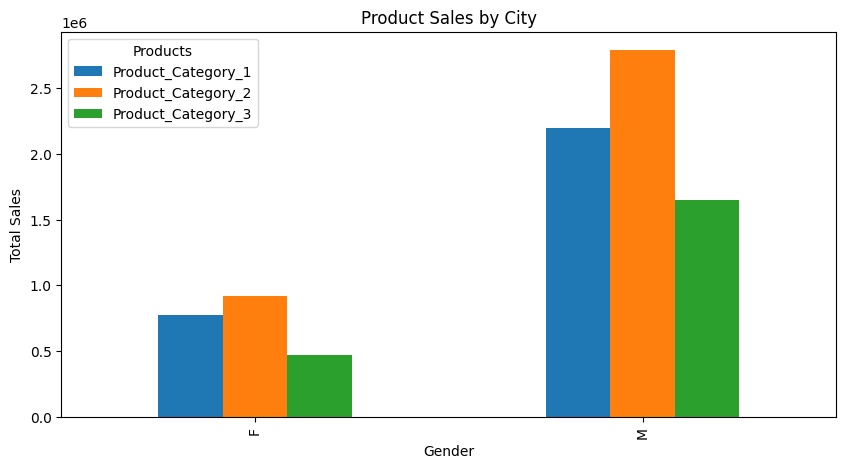

In [43]:
# group by city and sum products
city_product = df.groupby('Gender')[['Product_Category_1', 'Product_Category_2', 'Product_Category_3']].sum()

# print result
print(city_product)

# plot
city_product.plot(kind='bar', figsize=(10,5))
plt.title("Product Sales by City")
plt.ylabel("Total Sales")
plt.xlabel("Gender")
plt.legend(title="Products")
plt.show()

Demographic Distribution
Age: Majority of customers fall in the 26–35 age group, followed by 18–25 and 36–45. Older groups (46+, 55+) and minors (0–17) are much smaller segments.
Gender: Dataset is male-dominated (≈420k males vs 130k females). This imbalance means male purchasing behavior heavily influences overall trends.
Occupation: Certain occupations (0, 4) dominate in count, while others (8–11, 13–14, 18–19) are underrepresented. Spending patterns vary significantly by occupation, especially for females in occupation 18.
---> The dataset is skewed toward young, male customers in specific occupations. Models trained on this data must account for imbalance to avoid biased predictions.

Purchase Behaviour
Distribution: Purchases show a multimodal pattern with peaks around 5k–7k, suggesting distinct customer spending clusters (low, medium, high spenders).
Gender Impact: Males spend on average 8% more than females, making gender one of the strongest predictors.
Age Impact: Spending peaks in the 51–55 male group, but overall age is only a moderate predictor.
Occupation Impact: Certain occupations (12, 14, 15, 17 for males; 18 for females) show higher spending.
Marital Status: Very weak predictor (<2% variance). Married/unmarried differences are negligible.
---> Gender and occupation drive spending differences more than age or marital status.

Location & Tenure
City Category: City C customers consistently spend the most, across all demgraphics. This makes sity category strongest location perdictor.